
# Reproducing the core idea of Lagaris–Likas–Fotiadis (1998)

This notebook gives a **fully runnable modern reproduction** of the main method in the paper:

**Artificial Neural Networks for Solving Ordinary and Partial Differential Equations**

It implements the paper's central idea:

$$
\Psi_t(\mathbf{x}) = A(\mathbf{x}) + Z(\mathbf{x})N(\mathbf{x};\theta),
$$

where:
- $A$ satisfies the initial/boundary conditions,
- $Z$ vanishes on the constrained boundary (or is designed so the required derivative also vanishes),
- $N$ is a feedforward neural network,
- the training loss is the mean squared differential-equation residual on collocation points.

This notebook contains four runnable examples inspired by the paper:
1. first-order ODE,
2. second-order ODE with two-point boundary conditions,
3. a coupled ODE system,
4. a 2D Poisson PDE with Dirichlet boundary conditions.

It is a **teaching/reproduction notebook**, not a byte-for-byte historical reimplementation of the authors' original code/package. The original paper used a one-hidden-layer sigmoid network and quasi-Newton optimization; here we keep the same spirit and use PyTorch autograd with **sigmoid hidden units** plus **Adam + LBFGS** for stable training.


In [1]:

import math
import time
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cpu")
dtype = torch.float64
print("PyTorch version:", torch.__version__)
print("Device:", device)


PyTorch version: 2.5.1
Device: cpu



## 1. Utilities

We use one-hidden-layer feedforward networks with **sigmoid** activation to stay close to the original paper.


In [2]:

class ShallowNet(nn.Module):
    def __init__(self, in_dim, out_dim=1, hidden=20):
        super().__init__()
        self.fc1 = nn.Linear(in_dim, hidden)
        self.fc2 = nn.Linear(hidden, out_dim)
        self.act = nn.Sigmoid()
        self.double()

    def forward(self, x):
        return self.fc2(self.act(self.fc1(x)))


def grad(outputs, inputs, create_graph=True):
    return torch.autograd.grad(
        outputs,
        inputs,
        grad_outputs=torch.ones_like(outputs),
        create_graph=create_graph,
        retain_graph=True,
    )[0]


def second_derivative(y, x):
    dy = grad(y, x)
    d2y = grad(dy, x)
    return dy, d2y


def train_model(model, closure_loss_fn, adam_steps=1500, lbfgs_steps=200, adam_lr=1e-2, verbose=True):
    history = []

    # Adam warm-up
    opt = torch.optim.Adam(model.parameters(), lr=adam_lr)
    t0 = time.time()
    for step in range(adam_steps):
        opt.zero_grad()
        loss = closure_loss_fn()
        loss.backward()
        opt.step()
        history.append(float(loss.detach().cpu()))
        if verbose and (step + 1) % max(1, adam_steps // 5) == 0:
            print(f"Adam step {step+1:5d}/{adam_steps}: loss={history[-1]:.3e}")

    # LBFGS refinement
    if lbfgs_steps > 0:
        opt = torch.optim.LBFGS(
            model.parameters(),
            lr=1.0,
            max_iter=lbfgs_steps,
            tolerance_grad=1e-12,
            tolerance_change=1e-12,
            history_size=50,
            line_search_fn="strong_wolfe",
        )

        def closure():
            opt.zero_grad()
            loss = closure_loss_fn()
            loss.backward()
            return loss

        loss = opt.step(closure)
        history.append(float(loss.detach().cpu()))
        if verbose:
            print(f"LBFGS final reported loss: {history[-1]:.3e}")

    elapsed = time.time() - t0
    return history, elapsed


def plot_loss(history, title="Training loss"):
    plt.figure(figsize=(6, 4))
    plt.semilogy(history)
    plt.xlabel("iteration")
    plt.ylabel("loss")
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.show()


## 2. Example A — First-order ODE (paper-style trial solution)

We solve the paper's first ODE example in the form

$$
\Psi'(x) + \left(x + \frac{1+3x^2}{1+x+x^3}\right)\Psi(x)
= x^3 + 2x + x^2\frac{1+3x^2}{1+x+x^3}, \quad \Psi(0)=1.
$$

Its exact solution is

$$
\Psi_a(x)=x^2+\frac{e^{-x^2/2}}{1+x+x^3}.
$$

Following the paper, use the hard-constrained trial solution

$$
\Psi_t(x)=1+xN(x;\theta),
$$

which automatically satisfies $\Psi_t(0)=1$.


Adam step   240/1200: loss=1.714e-03
Adam step   480/1200: loss=4.723e-04
Adam step   720/1200: loss=3.235e-04
Adam step   960/1200: loss=5.496e-04
Adam step  1200/1200: loss=2.929e-04
LBFGS final reported loss: 2.929e-04
Elapsed time: 4.38 s


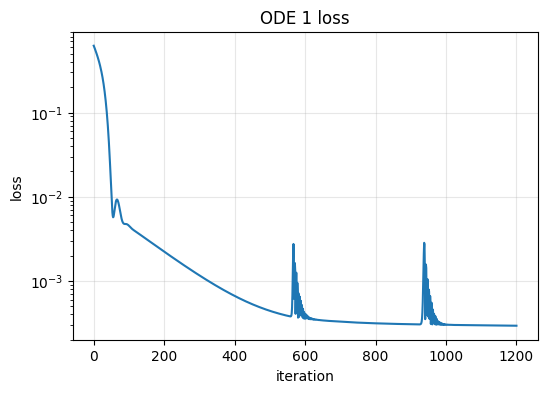

In [3]:

# Collocation points
x_train = torch.linspace(0.0, 1.0, 30, dtype=dtype, device=device).view(-1, 1)
x_train.requires_grad_(True)

# Model
net1 = ShallowNet(in_dim=1, out_dim=1, hidden=20).to(device)

# Exact solution and residual
def exact_ode1(x):
    return x**2 + torch.exp(-x**2 / 2.0) / (1.0 + x + x**3)


def trial_ode1(x):
    return 1.0 + x * net1(x)


def residual_ode1(x):
    psi = trial_ode1(x)
    dpsi = grad(psi, x)
    coeff = x + (1.0 + 3.0 * x**2) / (1.0 + x + x**3)
    rhs = x**3 + 2.0 * x + x**2 * (1.0 + 3.0 * x**2) / (1.0 + x + x**3)
    return dpsi + coeff * psi - rhs


def loss_ode1():
    r = residual_ode1(x_train)
    return torch.mean(r**2)

history1, t1 = train_model(net1, loss_ode1, adam_steps=1200, lbfgs_steps=120, adam_lr=1e-2)
print(f"Elapsed time: {t1:.2f} s")
plot_loss(history1, "ODE 1 loss")


ODE 1 max abs error on [0,1]: 0.002385341031981958
ODE 1 mean abs error on [0,1]: 0.0009687888186388816
ODE 1 boundary error at x=0: 0.0


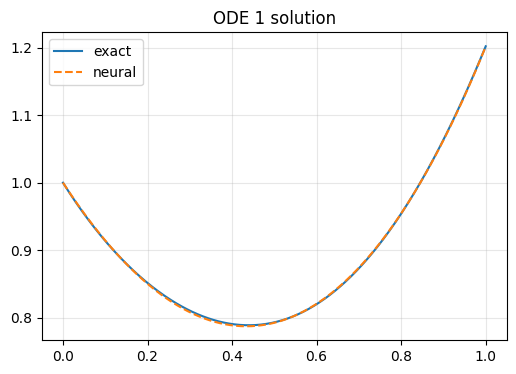

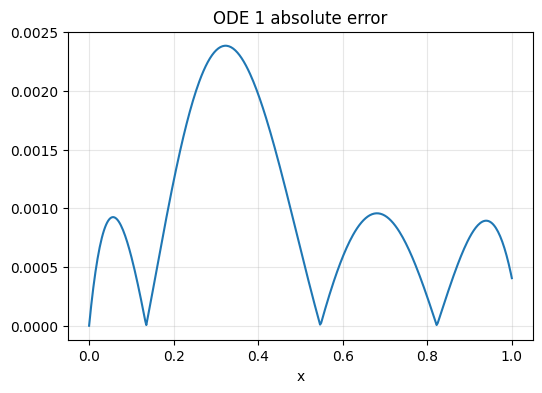

In [4]:

# Evaluation
x_test = torch.linspace(0.0, 1.0, 400, dtype=dtype, device=device).view(-1, 1)
x_test.requires_grad_(True)

with torch.no_grad():
    y_pred = trial_ode1(x_test)
    y_true = exact_ode1(x_test)
    err = (y_pred - y_true).abs()
    bc_error = abs(float(trial_ode1(torch.tensor([[0.0]], dtype=dtype)).item()) - 1.0)

print("ODE 1 max abs error on [0,1]:", float(err.max()))
print("ODE 1 mean abs error on [0,1]:", float(err.mean()))
print("ODE 1 boundary error at x=0:", bc_error)

plt.figure(figsize=(6,4))
plt.plot(x_test.detach().cpu(), y_true.detach().cpu(), label="exact")
plt.plot(x_test.detach().cpu(), y_pred.detach().cpu(), "--", label="neural")
plt.legend()
plt.title("ODE 1 solution")
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(6,4))
plt.plot(x_test.detach().cpu(), err.detach().cpu())
plt.title("ODE 1 absolute error")
plt.xlabel("x")
plt.grid(True, alpha=0.3)
plt.show()


ODE 1 max abs error on [0,1]: 0.6711198212864753
ODE 1 mean abs error on [0,1]: 0.194038020583874
ODE 1 boundary error at x=0: 0.0


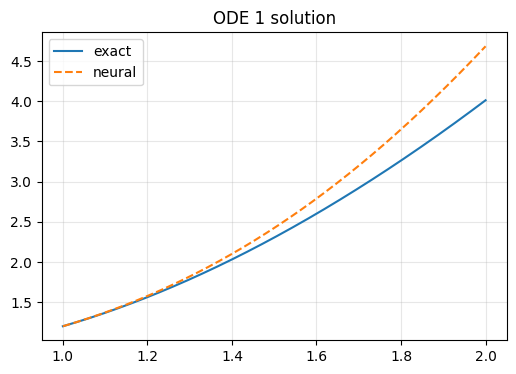

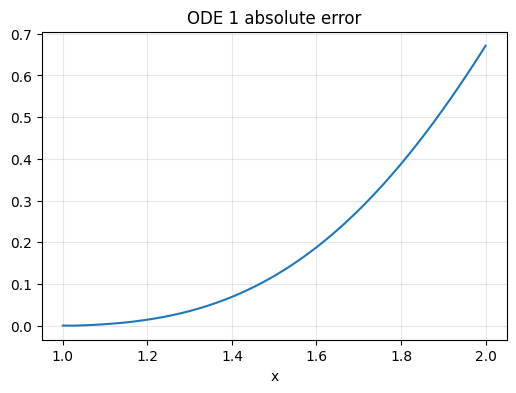

In [5]:
# Extrapolation
x_test = torch.linspace(1.0, 2.0, 400, dtype=dtype, device=device).view(-1, 1)
x_test.requires_grad_(True)

with torch.no_grad():
    y_pred = trial_ode1(x_test)
    y_true = exact_ode1(x_test)
    err = (y_pred - y_true).abs()
    bc_error = abs(float(trial_ode1(torch.tensor([[0.0]], dtype=dtype)).item()) - 1.0)

print("ODE 1 max abs error on [0,1]:", float(err.max()))
print("ODE 1 mean abs error on [0,1]:", float(err.mean()))
print("ODE 1 boundary error at x=0:", bc_error)

plt.figure(figsize=(6,4))
plt.plot(x_test.detach().cpu(), y_true.detach().cpu(), label="exact")
plt.plot(x_test.detach().cpu(), y_pred.detach().cpu(), "--", label="neural")
plt.legend()
plt.title("ODE 1 solution")
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(6,4))
plt.plot(x_test.detach().cpu(), err.detach().cpu())
plt.title("ODE 1 absolute error")
plt.xlabel("x")
plt.grid(True, alpha=0.3)
plt.show()

## 3. Example B — Second-order ODE with two-point boundary conditions

We solve

$$
\Psi''(x)+\frac{1}{5}\Psi'(x)+\Psi(x)=-\frac15 e^{-x/5}\cos x,
$$

with boundary conditions

$$
\Psi(0)=0, \qquad \Psi(1)=\sin(1)e^{-1/5}.
$$

The exact solution is

$$
\Psi_a(x)=e^{-x/5}\sin x.
$$

A hard-constrained trial solution analogous to the paper is

$$
\Psi_t(x)=x\,\Psi(1) + x(1-x)N(x;\theta).
$$



Adam step   280/1400: loss=1.500e-04
Adam step   560/1400: loss=6.237e-06
Adam step   840/1400: loss=2.601e-06
Adam step  1120/1400: loss=2.323e-06
Adam step  1400/1400: loss=2.033e-06
LBFGS final reported loss: 2.032e-06
Elapsed time: 4.51 s


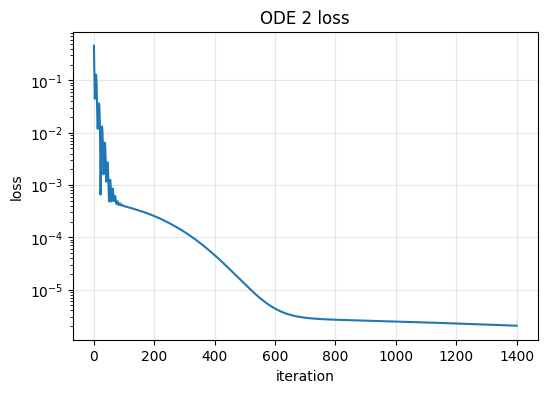

In [8]:

xb_train = torch.linspace(0.0, 1.0, 40, dtype=dtype, device=device).view(-1, 1)
xb_train.requires_grad_(True)

net2 = ShallowNet(in_dim=1, out_dim=1, hidden=20).to(device)
psi1_val = float(math.sin(1.0) * math.exp(-0.2))


def exact_ode2(x):
    return torch.exp(-x / 5.0) * torch.sin(x)


def trial_ode2(x):
    return psi1_val * x + x * (1.0 - x) * net2(x)


def residual_ode2(x):
    psi = trial_ode2(x)
    dpsi = grad(psi, x)
    d2psi = grad(dpsi, x)
    rhs = -(1.0 / 5.0) * torch.exp(-x / 5.0) * torch.cos(x)
    return d2psi + 0.2 * dpsi + psi - rhs


def loss_ode2():
    r = residual_ode2(xb_train)
    return torch.mean(r**2)

history2, t2 = train_model(net2, loss_ode2, adam_steps=1400, lbfgs_steps=140, adam_lr=1e-2)
print(f"Elapsed time: {t2:.2f} s")
plot_loss(history2, "ODE 2 loss")


ODE 2 max abs error on [0,1]: 7.360171191295173e-06
ODE 2 mean abs error on [0,1]: 3.7393848144054225e-06
ODE 2 BC error at x=0: 0.0
ODE 2 BC error at x=1: 0.0


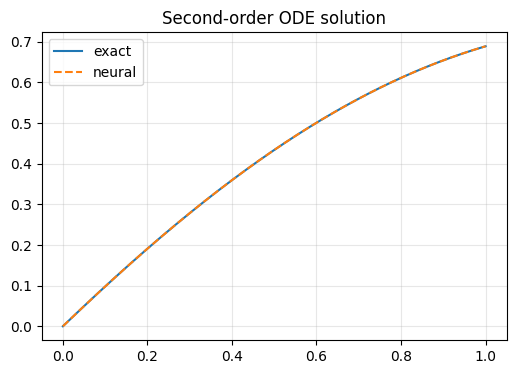

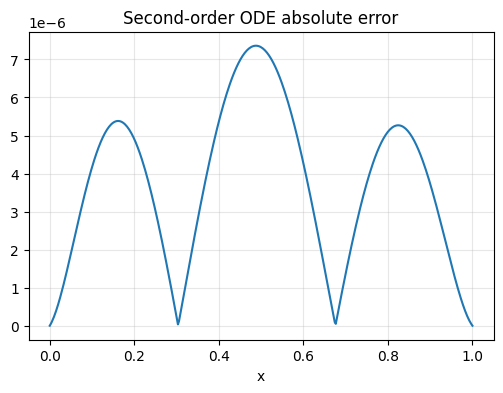

In [9]:

xb_test = torch.linspace(0.0, 1.0, 400, dtype=dtype, device=device).view(-1, 1)
with torch.no_grad():
    y_pred = trial_ode2(xb_test)
    y_true = exact_ode2(xb_test)
    err = (y_pred - y_true).abs()

bc0 = abs(float(trial_ode2(torch.tensor([[0.0]], dtype=dtype)).item()) - 0.0)
bc1 = abs(float(trial_ode2(torch.tensor([[1.0]], dtype=dtype)).item()) - psi1_val)
print("ODE 2 max abs error on [0,1]:", float(err.max()))
print("ODE 2 mean abs error on [0,1]:", float(err.mean()))
print("ODE 2 BC error at x=0:", bc0)
print("ODE 2 BC error at x=1:", bc1)

plt.figure(figsize=(6,4))
plt.plot(xb_test.detach().cpu(), y_true.detach().cpu(), label="exact")
plt.plot(xb_test.detach().cpu(), y_pred.detach().cpu(), "--", label="neural")
plt.legend()
plt.title("Second-order ODE solution")
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(6,4))
plt.plot(xb_test.detach().cpu(), err.detach().cpu())
plt.title("Second-order ODE absolute error")
plt.xlabel("x")
plt.grid(True, alpha=0.3)
plt.show()


ODE 2 max abs error on [0,1]: 0.015500602838625865
ODE 2 mean abs error on [0,1]: 0.00322540161501234
ODE 2 BC error at x=0: 0.0
ODE 2 BC error at x=1: 0.0


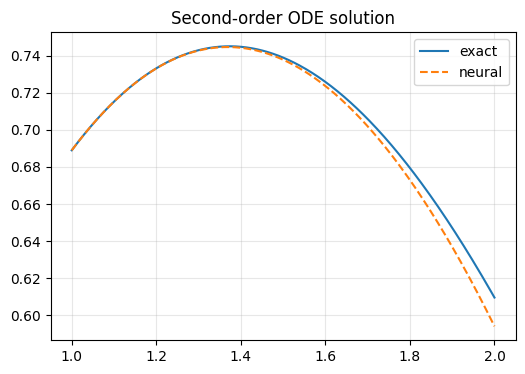

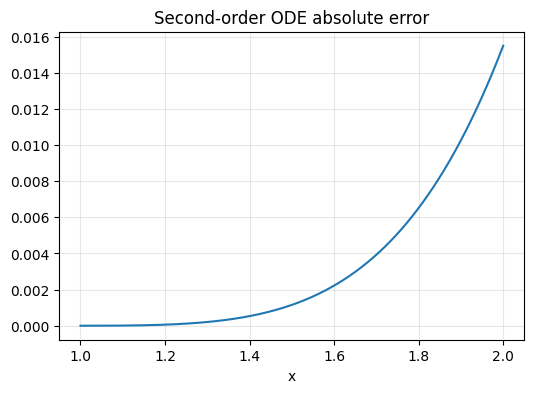

In [10]:
xb_test = torch.linspace(1.0, 2.0, 400, dtype=dtype, device=device).view(-1, 1)
with torch.no_grad():
    y_pred = trial_ode2(xb_test)
    y_true = exact_ode2(xb_test)
    err = (y_pred - y_true).abs()

bc0 = abs(float(trial_ode2(torch.tensor([[0.0]], dtype=dtype)).item()) - 0.0)
bc1 = abs(float(trial_ode2(torch.tensor([[1.0]], dtype=dtype)).item()) - psi1_val)
print("ODE 2 max abs error on [0,1]:", float(err.max()))
print("ODE 2 mean abs error on [0,1]:", float(err.mean()))
print("ODE 2 BC error at x=0:", bc0)
print("ODE 2 BC error at x=1:", bc1)

plt.figure(figsize=(6,4))
plt.plot(xb_test.detach().cpu(), y_true.detach().cpu(), label="exact")
plt.plot(xb_test.detach().cpu(), y_pred.detach().cpu(), "--", label="neural")
plt.legend()
plt.title("Second-order ODE solution")
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(6,4))
plt.plot(xb_test.detach().cpu(), err.detach().cpu())
plt.title("Second-order ODE absolute error")
plt.xlabel("x")
plt.grid(True, alpha=0.3)
plt.show()


## 4. Example C — Coupled first-order ODE system

We solve the system

$$
\begin{aligned}
\Psi_1'(x) &= \cos x + \Psi_1(x)^2 + \Psi_2(x) - (1+x^2+\sin^2 x),\\
\Psi_2'(x) &= 2x - (1+x^2)\sin x + \Psi_1(x)\Psi_2(x),
\end{aligned}
$$

with

$$
\Psi_1(0)=0, \qquad \Psi_2(0)=1.
$$

The exact solutions are

$$
\Psi_1(x)=\sin x, \qquad \Psi_2(x)=1+x^2.
$$

Using the paper's pattern,

$$
\Psi_{1,t}(x)=0+xN_1(x;\theta_1),\qquad
\Psi_{2,t}(x)=1+xN_2(x;\theta_2).
$$


Elapsed time: 8.19 s


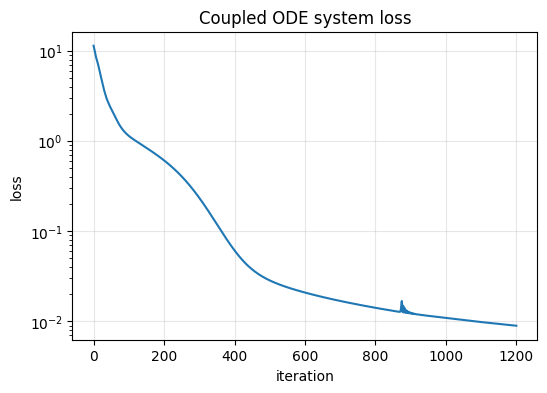

In [29]:
def train_system(params, closure_loss_fn, adam_steps=1200, lbfgs_steps=500, lr=5e-3):
    history = []
    t0 = time.time()

    opt = torch.optim.Adam(params, lr=lr)
    for step in range(adam_steps):
        opt.zero_grad()
        loss = closure_loss_fn()
        loss.backward()
        opt.step()
        history.append(float(loss.detach().cpu()))

    opt = torch.optim.LBFGS(
        params,
        lr=1.0,
        max_iter=lbfgs_steps,
        tolerance_grad=1e-12,
        tolerance_change=1e-12,
        history_size=50,
        line_search_fn="strong_wolfe"
    )

    def closure():
        opt.zero_grad()
        loss = closure_loss_fn()
        loss.backward()
        return loss

    loss = opt.step(closure)
    history.append(float(loss.detach().cpu()))

    return history, time.time() - t0
xc_train = torch.linspace(0.0, 3.0, 200, dtype=dtype, device=device).view(-1, 1)
xc_train.requires_grad_(True)

net3_1 = ShallowNet(in_dim=1, out_dim=1, hidden=10).to(device)
net3_2 = ShallowNet(in_dim=1, out_dim=1, hidden=10).to(device)
params3 = list(net3_1.parameters()) + list(net3_2.parameters())

def trial_sys1(x):
    return x * net3_1(x)

def trial_sys2(x):
    return 1.0 + x * net3_2(x)

def loss_system():
    u1 = trial_sys1(xc_train)
    u2 = trial_sys2(xc_train)
    du1 = grad(u1, xc_train)
    du2 = grad(u2, xc_train)

    r1 = du1 - (torch.cos(xc_train) + u1**2 + u2 - (1.0 + xc_train**2 + torch.sin(xc_train)**2))
    r2 = du2 - (2.0 * xc_train - (1.0 + xc_train**2) * torch.sin(xc_train) + u1 * u2)

    return torch.mean(r1**2 + r2**2)

history3, t3 = train_system(params3, loss_system, adam_steps=1200, lbfgs_steps=500, lr=5e-3)
print(f"Elapsed time: {t3:.2f} s")
plot_loss(history3, "Coupled ODE system loss")


System ODE max abs error for u1: 0.011567774553801008
System ODE mean abs error for u1: 0.00125287362896692
System ODE max abs error for u2: 0.03293723841889573
System ODE mean abs error for u2: 0.0030100975498416147


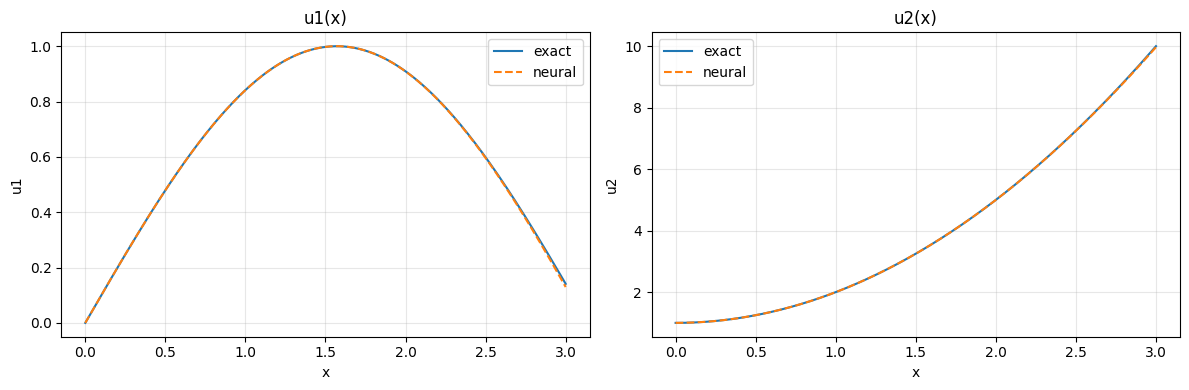

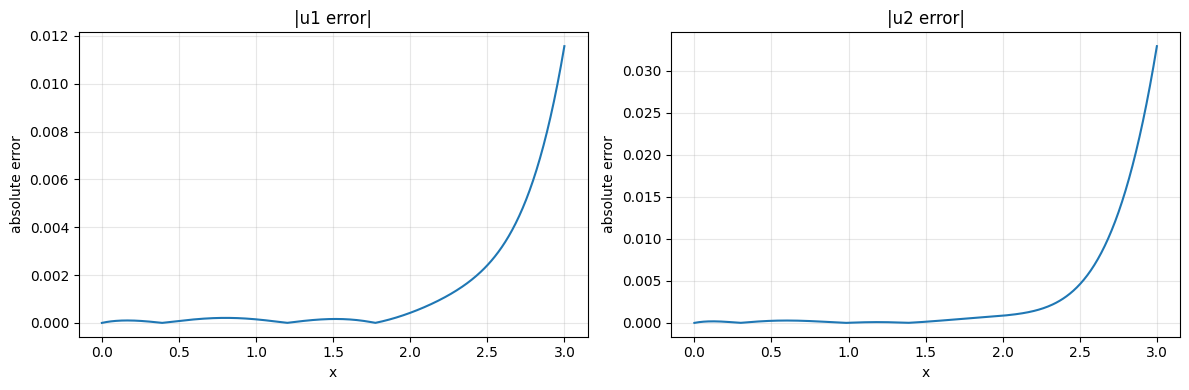

In [30]:

xc_test = torch.linspace(0.0, 3.0, 400, dtype=dtype, device=device).view(-1, 1)

with torch.no_grad():
    u1_pred = trial_sys1(xc_test)
    u2_pred = trial_sys2(xc_test)

    u1_true = torch.sin(xc_test)
    u2_true = 1.0 + xc_test**2

    err1 = (u1_pred - u1_true).abs()
    err2 = (u2_pred - u2_true).abs()

print("System ODE max abs error for u1:", float(err1.max().detach().cpu()))
print("System ODE mean abs error for u1:", float(err1.mean().detach().cpu()))
print("System ODE max abs error for u2:", float(err2.max().detach().cpu()))
print("System ODE mean abs error for u2:", float(err2.mean().detach().cpu()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(xc_test.detach().cpu().numpy(), u1_true.detach().cpu().numpy(), label="exact")
axes[0].plot(xc_test.detach().cpu().numpy(), u1_pred.detach().cpu().numpy(), "--", label="neural")
axes[0].set_title("u1(x)")
axes[0].set_xlabel("x")
axes[0].set_ylabel("u1")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(xc_test.detach().cpu().numpy(), u2_true.detach().cpu().numpy(), label="exact")
axes[1].plot(xc_test.detach().cpu().numpy(), u2_pred.detach().cpu().numpy(), "--", label="neural")
axes[1].set_title("u2(x)")
axes[1].set_xlabel("x")
axes[1].set_ylabel("u2")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(xc_test.detach().cpu().numpy(), err1.detach().cpu().numpy())
axes[0].set_title("|u1 error|")
axes[0].set_xlabel("x")
axes[0].set_ylabel("absolute error")
axes[0].grid(True, alpha=0.3)

axes[1].plot(xc_test.detach().cpu().numpy(), err2.detach().cpu().numpy())
axes[1].set_title("|u2 error|")
axes[1].set_xlabel("x")
axes[1].set_ylabel("absolute error")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()



## 5. Example D — 2D Poisson PDE on $[0,1]^2$ with Dirichlet boundary conditions

We solve the paper's PDE example

$$
\nabla^2\Psi(x,y)=e^{-x}(x-2+y^3+6y),
$$

with Dirichlet conditions

$$
\Psi(0,y)=y^3,
\quad \Psi(1,y)=(1+y^3)e^{-1},
\quad \Psi(x,0)=xe^{-x},
\quad \Psi(x,1)=e^{-x}(x+1).
$$

The exact solution is

$$
\Psi_a(x,y)=e^{-x}(x+y^3).
$$

A hard-constrained trial solution is

$$
\Psi_t(x,y)=A(x,y)+x(1-x)y(1-y)N(x,y;\theta),
$$

where $A(x,y)$ is built only from the boundary data. This is exactly the core idea of the paper.


Adam step   360/1800: loss=1.143e-04
Adam step   720/1800: loss=2.029e-05
Adam step  1080/1800: loss=8.390e-06
Adam step  1440/1800: loss=5.872e-06
Adam step  1800/1800: loss=4.281e-06
LBFGS final reported loss: 4.277e-06
Elapsed time: 31.75 s


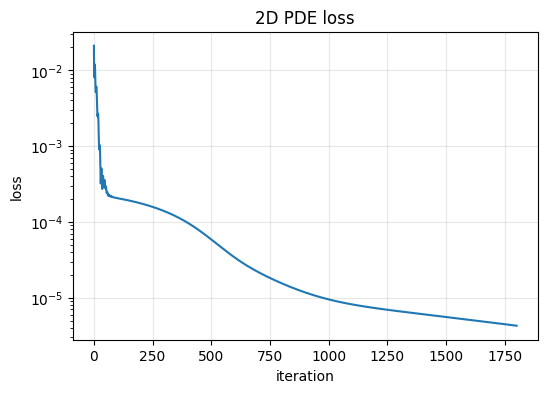

In [31]:

# Interior collocation grid
nx = 15
x = torch.linspace(0.0, 1.0, nx, dtype=dtype, device=device)
y = torch.linspace(0.0, 1.0, nx, dtype=dtype, device=device)
X, Y = torch.meshgrid(x, y, indexing="ij")
XY_train = torch.stack([X.reshape(-1), Y.reshape(-1)], dim=1)
XY_train.requires_grad_(True)

net4 = ShallowNet(in_dim=2, out_dim=1, hidden=24).to(device)

# Boundary data
f0 = lambda y: y**3                          # x = 0
g0 = lambda x: x * torch.exp(-x)            # y = 0
f1 = lambda y: (1.0 + y**3) * math.exp(-1)  # x = 1
g1 = lambda x: torch.exp(-x) * (x + 1.0)    # y = 1


def A_dirichlet(x, y):
    return ((1.0 - x) * f0(y) + x * f1(y) +
            (1.0 - y) * (g0(x) - ((1.0 - x) * g0(torch.tensor(0.0, dtype=dtype, device=device)) + x * g0(torch.tensor(1.0, dtype=dtype, device=device)))) +
            y * (g1(x) - ((1.0 - x) * g1(torch.tensor(0.0, dtype=dtype, device=device)) + x * g1(torch.tensor(1.0, dtype=dtype, device=device)))))


def exact_pde(x, y):
    return torch.exp(-x) * (x + y**3)


def trial_pde(xy):
    x = xy[:, 0:1]
    y = xy[:, 1:2]
    a = A_dirichlet(x, y)
    z = x * (1.0 - x) * y * (1.0 - y)
    return a + z * net4(xy)


def residual_pde(xy):
    psi = trial_pde(xy)
    g = grad(psi, xy)
    psi_x = g[:, 0:1]
    psi_y = g[:, 1:2]
    psi_xx = grad(psi_x, xy)[:, 0:1]
    psi_yy = grad(psi_y, xy)[:, 1:2]
    x = xy[:, 0:1]
    y = xy[:, 1:2]
    rhs = torch.exp(-x) * (x - 2.0 + y**3 + 6.0 * y)
    return psi_xx + psi_yy - rhs


def loss_pde():
    r = residual_pde(XY_train)
    return torch.mean(r**2)

history4, t4 = train_model(net4, loss_pde, adam_steps=1800, lbfgs_steps=120, adam_lr=8e-3)
print(f"Elapsed time: {t4:.2f} s")
plot_loss(history4, "2D PDE loss")


PDE max abs error on test grid: 3.929698941318449e-05
PDE mean abs error on test grid: 1.2636255654391643e-05
Boundary max error (x=0): 0.0
Boundary max error (x=1): 0.0
Boundary max error (y=0): 0.0
Boundary max error (y=1): 0.0


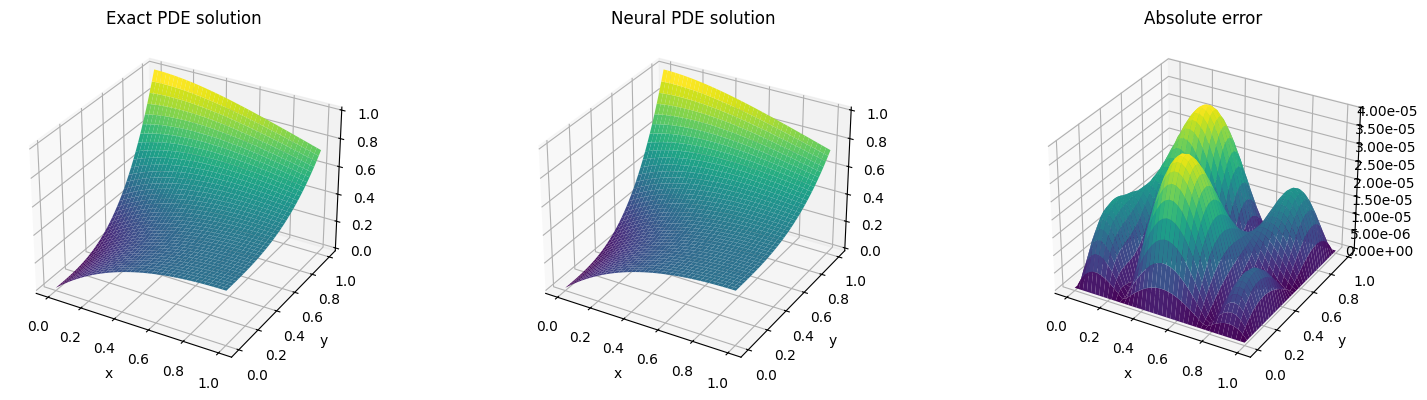

In [32]:

# Evaluate on a finer grid
n_test = 41
xt = torch.linspace(0.0, 1.0, n_test, dtype=dtype, device=device)
yt = torch.linspace(0.0, 1.0, n_test, dtype=dtype, device=device)
Xt, Yt = torch.meshgrid(xt, yt, indexing="ij")
XY_test = torch.stack([Xt.reshape(-1), Yt.reshape(-1)], dim=1)

with torch.no_grad():
    U_pred = trial_pde(XY_test).reshape(n_test, n_test)
    U_true = exact_pde(Xt, Yt)
    U_err = (U_pred - U_true).abs()

print("PDE max abs error on test grid:", float(U_err.max()))
print("PDE mean abs error on test grid:", float(U_err.mean()))

# Boundary checks
with torch.no_grad():
    ys = torch.linspace(0, 1, 50, dtype=dtype, device=device).view(-1, 1)
    xs = torch.linspace(0, 1, 50, dtype=dtype, device=device).view(-1, 1)

    left = trial_pde(torch.cat([torch.zeros_like(ys), ys], dim=1)) - ys**3
    right = trial_pde(torch.cat([torch.ones_like(ys), ys], dim=1)) - (1 + ys**3) * math.exp(-1)
    bottom = trial_pde(torch.cat([xs, torch.zeros_like(xs)], dim=1)) - xs * torch.exp(-xs)
    top = trial_pde(torch.cat([xs, torch.ones_like(xs)], dim=1)) - torch.exp(-xs) * (xs + 1)

print("Boundary max error (x=0):", float(left.abs().max()))
print("Boundary max error (x=1):", float(right.abs().max()))
print("Boundary max error (y=0):", float(bottom.abs().max()))
print("Boundary max error (y=1):", float(top.abs().max()))

# Surface plots
fig = plt.figure(figsize=(16, 4))
ax1 = fig.add_subplot(131, projection='3d')
ax2 = fig.add_subplot(132, projection='3d')
ax3 = fig.add_subplot(133, projection='3d')

ax1.plot_surface(Xt.cpu().numpy(), Yt.cpu().numpy(), U_true.cpu().numpy(), cmap='viridis')
ax1.set_title('Exact PDE solution')
ax1.set_xlabel('x')
ax1.set_ylabel('y')

ax2.plot_surface(Xt.cpu().numpy(), Yt.cpu().numpy(), U_pred.cpu().numpy(), cmap='viridis')
ax2.set_title('Neural PDE solution')
ax2.set_xlabel('x')
ax2.set_ylabel('y')

ax3.plot_surface(Xt.cpu().numpy(), Yt.cpu().numpy(), U_err.cpu().numpy(), cmap='viridis')
ax3.set_title('Absolute error')
ax3.set_xlabel('x')
ax3.set_ylabel('y')
ax3.zaxis.set_major_formatter(plt.FuncFormatter(lambda v, p: f'{v:.2e}'))
plt.tight_layout()
plt.show()


FEM elapsed time: 0.2340 s
FEM nodal max abs error: 7.650789434521243e-05
FEM nodal mean abs error: 3.0164791069540455e-05


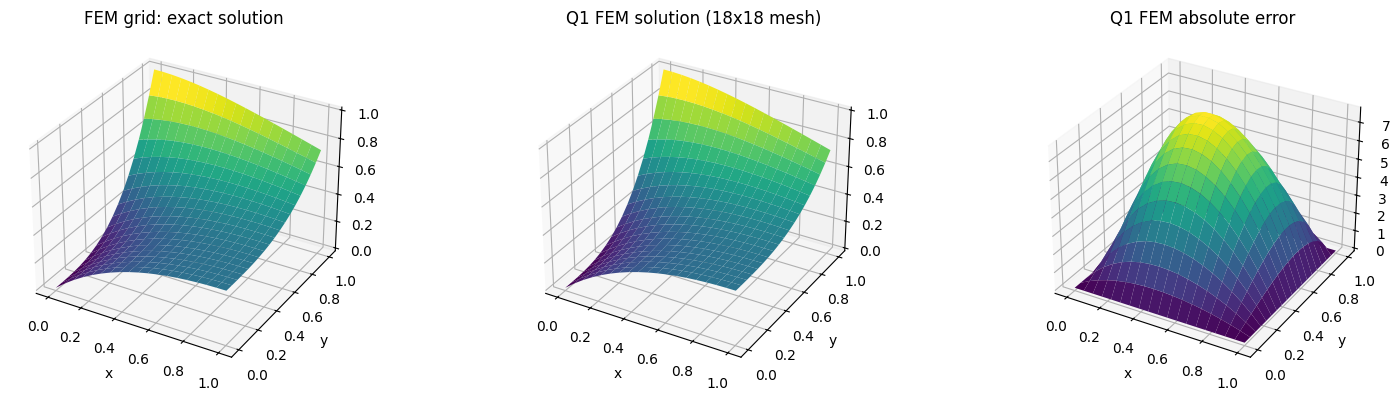

NN max abs error on FEM nodal grid: 3.889502865139782e-05
NN mean abs error on FEM nodal grid: 1.1792396386219797e-05
                           Method   Time (s)  Max abs error  Mean abs error
0  Neural hard-constrained method  31.748330       0.000039        0.000012
1             Q1 FEM (18x18 mesh)   0.233989       0.000077        0.000030


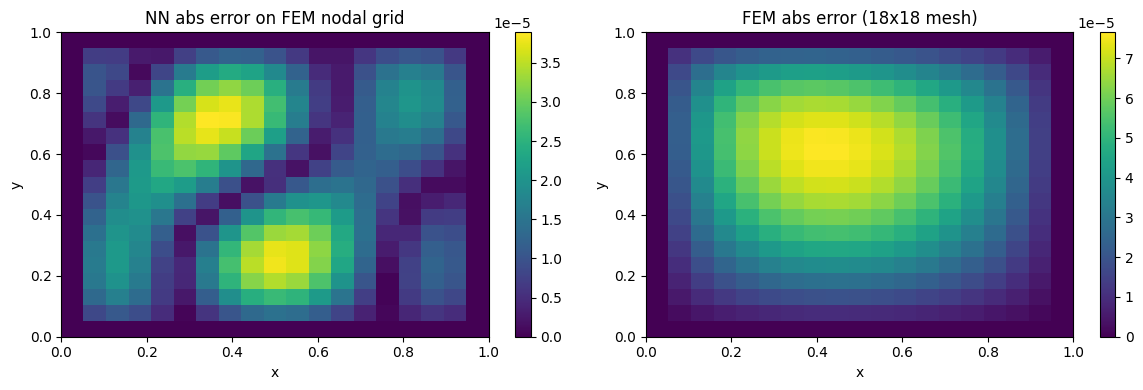

In [33]:
import numpy as np
import math
import time
import matplotlib.pyplot as plt

from scipy.sparse import lil_matrix, csr_matrix
from scipy.sparse.linalg import spsolve


# =========================================================
# 1) Problem definition
# =========================================================
def rhs_np(x, y):
    return np.exp(-x) * (x - 2.0 + y**3 + 6.0 * y)

def exact_np(x, y):
    return np.exp(-x) * (x + y**3)

def bc_np(x, y):
    return exact_np(x, y)


# =========================================================
# 2) Q1 bilinear FEM on a structured Nx x Ny mesh
#    Here "18x18 mesh" means 18 elements in x and 18 in y
# =========================================================
Nx_fem = 18
Ny_fem = 18

hx = 1.0 / Nx_fem
hy = 1.0 / Ny_fem

x_nodes = np.linspace(0.0, 1.0, Nx_fem + 1)
y_nodes = np.linspace(0.0, 1.0, Ny_fem + 1)

# node indexing: id(i,j) = i*(Ny_fem+1) + j
def node_id(i, j):
    return i * (Ny_fem + 1) + j

n_nodes = (Nx_fem + 1) * (Ny_fem + 1)

# coordinates of all nodes
coords = np.zeros((n_nodes, 2))
for i in range(Nx_fem + 1):
    for j in range(Ny_fem + 1):
        idx = node_id(i, j)
        coords[idx, 0] = x_nodes[i]
        coords[idx, 1] = y_nodes[j]


# =========================================================
# 3) Reference Q1 basis on [-1,1]^2
# =========================================================
def shape_funcs(xi, eta):
    # order: bottom-left, bottom-right, top-right, top-left
    N1 = 0.25 * (1 - xi) * (1 - eta)
    N2 = 0.25 * (1 + xi) * (1 - eta)
    N3 = 0.25 * (1 + xi) * (1 + eta)
    N4 = 0.25 * (1 - xi) * (1 + eta)
    return np.array([N1, N2, N3, N4])

def shape_grads_ref(xi, eta):
    # derivatives w.r.t. reference coords (xi, eta)
    dN_dxi = np.array([
        -0.25 * (1 - eta),
         0.25 * (1 - eta),
         0.25 * (1 + eta),
        -0.25 * (1 + eta)
    ])
    dN_deta = np.array([
        -0.25 * (1 - xi),
        -0.25 * (1 + xi),
         0.25 * (1 + xi),
         0.25 * (1 - xi)
    ])
    return dN_dxi, dN_deta


# =========================================================
# 4) Local element matrices:
#    We solve  Delta u = f
#    Weak form is: integral grad(u).grad(v) = - integral f v
#    because standard FEM is usually written for -Delta u = g
#    so here g = -f.
# =========================================================
gauss_pts = [-1.0 / np.sqrt(3.0), 1.0 / np.sqrt(3.0)]
gauss_wts = [1.0, 1.0]

A = lil_matrix((n_nodes, n_nodes))
b = np.zeros(n_nodes)

t0_fem = time.time()

for ex in range(Nx_fem):
    for ey in range(Ny_fem):
        # element corner nodes
        n1 = node_id(ex,     ey)
        n2 = node_id(ex + 1, ey)
        n3 = node_id(ex + 1, ey + 1)
        n4 = node_id(ex,     ey + 1)
        elem = [n1, n2, n3, n4]

        xL, xR = x_nodes[ex], x_nodes[ex + 1]
        yB, yT = y_nodes[ey], y_nodes[ey + 1]

        # affine rectangle mapping
        J = np.array([[hx / 2.0, 0.0],
                      [0.0, hy / 2.0]])
        detJ = np.linalg.det(J)
        invJT = np.linalg.inv(J).T

        Ke = np.zeros((4, 4))
        Fe = np.zeros(4)

        for xi, wx in zip(gauss_pts, gauss_wts):
            for eta, wy in zip(gauss_pts, gauss_wts):
                wq = wx * wy

                N = shape_funcs(xi, eta)
                dN_dxi, dN_deta = shape_grads_ref(xi, eta)

                grads_phys = []
                for a in range(4):
                    grad_ref = np.array([dN_dxi[a], dN_deta[a]])
                    grad_phys = invJT @ grad_ref
                    grads_phys.append(grad_phys)
                grads_phys = np.array(grads_phys)

                # physical quadrature point
                xq = 0.5 * (xL + xR) + 0.5 * hx * xi
                yq = 0.5 * (yB + yT) + 0.5 * hy * eta

                fq = rhs_np(xq, yq)

                # stiffness
                for a in range(4):
                    for c in range(4):
                        Ke[a, c] += np.dot(grads_phys[a], grads_phys[c]) * detJ * wq

                # load for Delta u = f  =>  -Delta u = -f
                # so RHS in standard weak form is -f
                for a in range(4):
                    Fe[a] += (-fq) * N[a] * detJ * wq

        # assemble
        for a in range(4):
            A[elem[a], elem[a]] += 0.0  # keep shape
            b[elem[a]] += Fe[a]
            for c in range(4):
                A[elem[a], elem[c]] += Ke[a, c]


# =========================================================
# 5) Strong Dirichlet boundary conditions
# =========================================================
boundary_nodes = []
interior_nodes = []

u_bc = np.zeros(n_nodes)

for i in range(Nx_fem + 1):
    for j in range(Ny_fem + 1):
        idx = node_id(i, j)
        xij, yij = coords[idx]

        if i == 0 or i == Nx_fem or j == 0 or j == Ny_fem:
            boundary_nodes.append(idx)
            u_bc[idx] = bc_np(xij, yij)
        else:
            interior_nodes.append(idx)

boundary_nodes = np.array(boundary_nodes, dtype=int)
interior_nodes = np.array(interior_nodes, dtype=int)

A = A.tocsr()

# adjust RHS: b_I <- b_I - A_IB * u_B
b_mod = b.copy()
b_mod[interior_nodes] -= A[interior_nodes][:, boundary_nodes] @ u_bc[boundary_nodes]

# reduced system
A_II = A[interior_nodes][:, interior_nodes]
b_II = b_mod[interior_nodes]

u_fem = np.zeros(n_nodes)
u_fem[boundary_nodes] = u_bc[boundary_nodes]
u_fem[interior_nodes] = spsolve(A_II, b_II)

t_fem = time.time() - t0_fem


# =========================================================
# 6) FEM errors at nodes
# =========================================================
u_exact_nodes = exact_np(coords[:, 0], coords[:, 1])
u_err_nodes = np.abs(u_fem - u_exact_nodes)

print(f"FEM elapsed time: {t_fem:.4f} s")
print("FEM nodal max abs error:", float(u_err_nodes.max()))
print("FEM nodal mean abs error:", float(u_err_nodes.mean()))


# =========================================================
# 7) Reshape for plotting
# =========================================================
U_fem = np.zeros((Nx_fem + 1, Ny_fem + 1))
U_exact_fem = np.zeros((Nx_fem + 1, Ny_fem + 1))
U_err_fem = np.zeros((Nx_fem + 1, Ny_fem + 1))

for i in range(Nx_fem + 1):
    for j in range(Ny_fem + 1):
        idx = node_id(i, j)
        U_fem[i, j] = u_fem[idx]
        U_exact_fem[i, j] = u_exact_nodes[idx]
        U_err_fem[i, j] = u_err_nodes[idx]

Xf, Yf = np.meshgrid(x_nodes, y_nodes, indexing="ij")


# =========================================================
# 8) FEM plots
# =========================================================
fig = plt.figure(figsize=(16, 4))

ax1 = fig.add_subplot(131, projection='3d')
ax1.plot_surface(Xf, Yf, U_exact_fem, cmap='viridis')
ax1.set_title('FEM grid: exact solution')
ax1.set_xlabel('x')
ax1.set_ylabel('y')

ax2 = fig.add_subplot(132, projection='3d')
ax2.plot_surface(Xf, Yf, U_fem, cmap='viridis')
ax2.set_title('Q1 FEM solution (18x18 mesh)')
ax2.set_xlabel('x')
ax2.set_ylabel('y')

ax3 = fig.add_subplot(133, projection='3d')
ax3.plot_surface(Xf, Yf, U_err_fem, cmap='viridis')
ax3.set_title('Q1 FEM absolute error')
ax3.set_xlabel('x')
ax3.set_ylabel('y')

plt.tight_layout()
plt.show()


# =========================================================
# 9) Compare with your neural method on the SAME 19x19 nodal grid
#    (18x18 elements => 19x19 nodes)
# =========================================================
XY_compare_torch = torch.tensor(
    np.stack([Xf.reshape(-1), Yf.reshape(-1)], axis=1),
    dtype=dtype,
    device=device
)

with torch.no_grad():
    U_nn_compare = trial_pde(XY_compare_torch).reshape(Nx_fem + 1, Ny_fem + 1).cpu().numpy()

U_exact_compare = U_exact_fem
U_nn_err = np.abs(U_nn_compare - U_exact_compare)

print("NN max abs error on FEM nodal grid:", float(U_nn_err.max()))
print("NN mean abs error on FEM nodal grid:", float(U_nn_err.mean()))


# =========================================================
# 10) Unified comparison table
# =========================================================
try:
    nn_train_time = t4
except NameError:
    nn_train_time = np.nan

comparison = {
    "Method": ["Neural hard-constrained method", "Q1 FEM (18x18 mesh)"],
    "Time (s)": [float(nn_train_time), float(t_fem)],
    "Max abs error": [float(U_nn_err.max()), float(U_err_fem.max())],
    "Mean abs error": [float(U_nn_err.mean()), float(U_err_fem.mean())],
}

import pandas as pd
df_compare = pd.DataFrame(comparison)
print(df_compare)


# =========================================================
# 11) Side-by-side error heatmaps
# =========================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

im1 = axes[0].imshow(U_nn_err.T, origin='lower', extent=[0, 1, 0, 1], aspect='auto', cmap='viridis')
axes[0].set_title('NN abs error on FEM nodal grid')
axes[0].set_xlabel('x')
axes[0].set_ylabel('y')
plt.colorbar(im1, ax=axes[0])

im2 = axes[1].imshow(U_err_fem.T, origin='lower', extent=[0, 1, 0, 1], aspect='auto', cmap='viridis')
axes[1].set_title('FEM abs error (18x18 mesh)')
axes[1].set_xlabel('x')
axes[1].set_ylabel('y')
plt.colorbar(im2, ax=axes[1])

plt.tight_layout()
plt.show()

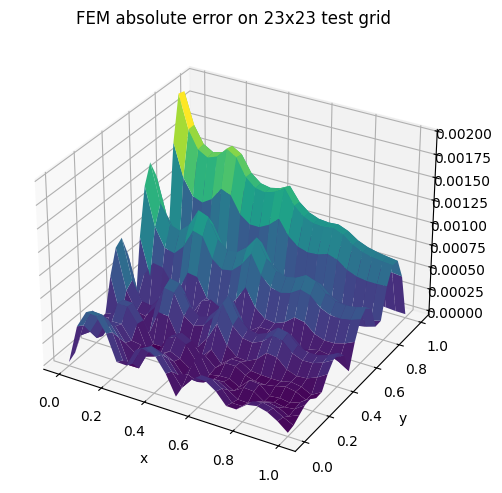

In [36]:
# FEM absolute error only on a 23x23 test grid

Nx_test = 23
Ny_test = 23

x_test = np.linspace(0.0, 1.0, Nx_test)
y_test = np.linspace(0.0, 1.0, Ny_test)
Xt, Yt = np.meshgrid(x_test, y_test, indexing="ij")

def fem_eval_point(x, y, u_vec):
    if x >= 1.0:
        ex = Nx_fem - 1
        xi = 1.0
    else:
        ex = min(int(x / hx), Nx_fem - 1)
        xL = x_nodes[ex]
        xi = 2.0 * (x - xL) / hx - 1.0

    if y >= 1.0:
        ey = Ny_fem - 1
        eta = 1.0
    else:
        ey = min(int(y / hy), Ny_fem - 1)
        yB = y_nodes[ey]
        eta = 2.0 * (y - yB) / hy - 1.0

    n1 = node_id(ex,     ey)
    n2 = node_id(ex + 1, ey)
    n3 = node_id(ex + 1, ey + 1)
    n4 = node_id(ex,     ey + 1)
    elem = [n1, n2, n3, n4]

    N = shape_funcs(xi, eta)
    return np.dot(N, u_vec[elem])

U_fem_test = np.zeros((Nx_test, Ny_test))
for i in range(Nx_test):
    for j in range(Ny_test):
        U_fem_test[i, j] = fem_eval_point(Xt[i, j], Yt[i, j], u_fem)

U_exact_test = exact_np(Xt, Yt)
U_err_test = np.abs(U_fem_test - U_exact_test)

fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(Xt, Yt, U_err_test, cmap='viridis')
ax.set_title('FEM absolute error on 23x23 test grid')
ax.set_xlabel('x')
ax.set_ylabel('y')
plt.tight_layout()
plt.show()


## 6. Summary

This notebook demonstrates the full workflow advocated by the paper:

1. **Design a trial solution** that satisfies the IC/BC exactly.
2. **Use a neural network only for the unconstrained part.**
3. **Train by minimizing the differential-equation residual** on collocation points.
4. Evaluate the learned analytic surrogate on dense test points.

### What this notebook reproduces faithfully
- one-hidden-layer feedforward network,
- sigmoid hidden units,
- hard enforcement of IC/BC through trial functions,
- collocation residual minimization,
- ODE / system / PDE examples.

### What is modernized
- PyTorch automatic differentiation instead of hand-derived gradient formulas,
- Adam + LBFGS instead of the exact historical optimization setup,
- compact pedagogical implementation.

If you want, the natural next extension is to add:
- the paper's **mixed boundary PDE** example,
- the **nonlinear PDE** example,
- a small **FEM comparison** section,
- or a version rewritten in a more report-ready style for coursework submission.
